## Theory

$$B_N = \frac{\int |H(f)|^2\,df}{|H(f_0)|^2} = \frac{\sum_i P_i\,\Delta f}{P_\mathrm{peak}}$$

after removing the noise floor: a swept trace of a clean tone *is* the power response of the RBW filter.

The analog RBW filters are four synchronously tuned poles (Agilent AN 150, AN 1303):

$$|H(f)|^2 = \left[1 + (f/a)^2\right]^{-4}, \qquad
B_{3\,\mathrm{dB}} = 2a\sqrt{2^{1/4}-1}, \qquad
B_N = \frac{5\pi}{16}\,a = 1.128\,B_{3\,\mathrm{dB}}$$

The nominal RBW is the −3 dB width but only to ±15 % (datasheet), so $B_N$ is taken from the trace and
checked against $1.128 \times B_{3\,\mathrm{dB}}$.

In [1]:
import json
from math import pi, sqrt
import numpy as np
import matplotlib.pyplot as plt

## Parameters

In [2]:
ON_FILE = "100khz_rbw_sa_signal_on.json"      # probe on
OFF_FILE = "100khz_rbw_sa_signal_off.json"    # probe off, same SA settings: the noise floor

## Load the traces

In [3]:
def load(name):
    with open(name) as fh:
        d = json.load(fh)
    return d, d["trace"]

d_on, t_on = load(ON_FILE)
d_off, t_off = load(OFF_FILE)
f = np.array(t_on["x"])
y = np.array(t_on["y"])                       # dBm
P = 10 ** (y / 10) * 1e-3                     # W
P_off = 10 ** (np.array(t_off["y"]) / 10) * 1e-3
df = f[1] - f[0]
assert np.array_equal(f, np.array(t_off["x"]))
for k in ("span_hz", "rbw_hz", "vbw_hz", "scale", "averages"):
    assert t_on[k] == t_off[k], k

sa, probe = d_on["instruments"]["spa"], d_on["instruments"]["rf_probe"]
print(f"span {t_on['span_hz']/1e6:g} MHz, RBW {t_on['rbw_hz']/1e3:g} kHz, VBW {t_on['vbw_hz']/1e3:g} kHz, "
      f"{sa['detector']} detector, {t_on['scale']}, sweep {sa['sweep_time_s']:g} s, {t_on['averages']} averages, "
      f"ref level {sa['ref_level']:g} dBm, {len(f)} points, df = {df/1e3:g} kHz")
print(f"tone: SMW200A {probe['probe_frequency_hz']/1e9:g} GHz, {probe['probe_power_dbm']:g} dBm, "
      f"RCDAT {d_on['instruments']['attenuator']['attenuation_db']:g} dB; "
      f"off trace: probe {'on' if d_off['instruments']['rf_probe']['probe_enable'] else 'off'}")

span 2 MHz, RBW 100 kHz, VBW 3000 kHz, AVER detector, LOG, sweep 2 s, 10 averages, ref level -20 dBm, 401 points, df = 5 kHz
tone: SMW200A 5.576 GHz, 0 dBm, RCDAT 0 dB; off trace: probe off


## ENBW and −3 dB width

In [4]:
floor_w = P_off.mean()                        # flat: both halves agree (printed below)
floor_dbm = 10 * np.log10(floor_w / 1e-3)

# peak: parabola through the top 7 points in dB
ip = np.argmax(y)
c2, c1, c0 = np.polyfit(f[ip-3:ip+4] - f[ip], y[ip-3:ip+4], 2)
f_peak = f[ip] - c1 / (2 * c2)
y_peak = c0 - c1 ** 2 / (4 * c2)
peak_w = 10 ** (y_peak / 10) * 1e-3 - floor_w

s = (P - floor_w) / peak_w                    # |H|^2, 1 at the peak
enbw = s.sum() * df

i = np.where(s >= 0.5)[0]
lo = np.interp(0.5, [s[i[0]-1], s[i[0]]], [f[i[0]-1], f[i[0]]])
hi = np.interp(0.5, [s[i[-1]+1], s[i[-1]]], [f[i[-1]+1], f[i[-1]]])
b3 = hi - lo
ratio_4pole = (5 * pi / 16) / (2 * sqrt(2 ** 0.25 - 1))

half = len(P_off) // 2
print(f"floor {floor_dbm:.2f} dBm (halves {10*np.log10(P_off[:half].mean()/1e-3):.2f} / "
      f"{10*np.log10(P_off[half:].mean()/1e-3):.2f} dBm)")
print(f"peak {y_peak:.2f} dBm at {f_peak/1e9:.6f} GHz, {y_peak - floor_dbm:.1f} dB above the floor")
print(f"-3 dB width  B3 = {b3/1e3:.2f} kHz")
print(f"ENBW         BN = {enbw/1e3:.2f} kHz  (measured, area / peak)")
print(f"4-pole       BN = {ratio_4pole:.4f} x B3 = {ratio_4pole*b3/1e3:.2f} kHz  "
      f"(measured / 4-pole = {enbw/(ratio_4pole*b3):.4f})")
print(f"floor contributes {floor_w * len(f) * df / peak_w:.1f} Hz to the area before it is removed")
x = f - f_peak
print(f"area beyond +-300 kHz: {s[np.abs(x) > 3e5].sum()*df:.0f} Hz")

floor -85.23 dBm (halves -85.22 / -85.24 dBm)
peak -32.73 dBm at 5.575997 GHz, 52.5 dB above the floor
-3 dB width  B3 = 100.31 kHz
ENBW         BN = 113.17 kHz  (measured, area / peak)
4-pole       BN = 1.1285 x B3 = 113.20 kHz  (measured / 4-pole = 0.9997)
floor contributes 11.3 Hz to the area before it is removed
area beyond +-300 kHz: 26 Hz


## Shape vs the 4-pole filter

The model curve has the measured −3 dB width. The trace follows it on both sides down to about −45 dB,
where the floor's scatter (10 averages) takes over. Unlike the RBW 1 MHz trace taken at VBW 1 kHz, it shows no
smearing to one side (VBW 3 MHz, 2 s sweep). The area beyond ±300 kHz is ~0.02 % of $B_N$, so the 2 MHz span
holds the whole filter.

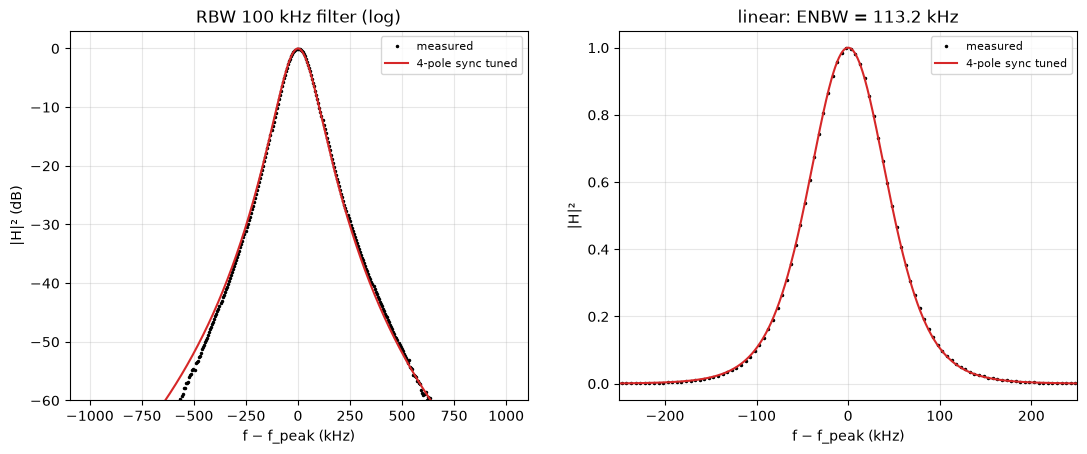

In [5]:
xm = np.linspace(x[0], x[-1], 2001)
a = b3 / (2 * sqrt(2 ** 0.25 - 1))
model = (1 + (xm / a) ** 2) ** -4

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(x / 1e3, 10 * np.log10(np.maximum(s, 1e-9)), "k.", ms=3, label="measured")
ax[0].plot(xm / 1e3, 10 * np.log10(model), "C3", label="4-pole sync tuned")
ax[1].plot(x / 1e3, s, "k.", ms=3, label="measured")
ax[1].plot(xm / 1e3, model, "C3", label="4-pole sync tuned")
ax[0].set(xlabel="f − f_peak (kHz)", ylabel="|H|² (dB)", ylim=(-60, 3), title="RBW 100 kHz filter (log)")
ax[1].set(xlabel="f − f_peak (kHz)", ylabel="|H|²", xlim=(-250, 250), title=f"linear: ENBW = {enbw/1e3:.1f} kHz")
for a_ in ax:
    a_.grid(alpha=0.3)
    a_.legend(fontsize=8)
plt.show()